# How unnecessary conditioning creates bias

This native Julia companion preserves the original structural equations, causal targets, parameters, sample sizes, seeds, repetitions and decision rules. Preserved primitive NumPy draws retain the original samples; Julia generates the observations and computes all estimates. Native exception checks cover the corresponding rejection conditions. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

Suppose the outcome causes part of a variable that is also caused by the exposure:

$$
Y=\beta X+U,
\qquad
Z=\gamma Y+\delta X+V,
\qquad
\widehat\beta=\frac{\beta-\delta\gamma}{1+\gamma^2},
\qquad
\widehat\theta=\frac{\gamma}{1+\gamma^2}.
$$

Here, $X$ is the exposure, $Y$ is the outcome, $Z$ is their common outcome and therefore a collider, $U$ and $V$ are independent centered unit-variance disturbances, $\beta$ is the causal effect of $X$ on $Y$, $\gamma$ links $Y$ to $Z$, $\delta$ links $X$ to $Z$, and $\widehat\beta$ and $\widehat\theta$ are the population coefficients on $X$ and $Z$ after conditioning on the collider.

Row,Direct effect,Outcome-to-collider link,Exposure-to-collider link,Conditioned exposure coefficient,Conditioned collider coefficient,Exposure-coefficient error
,Float64,Float64,Float64,Float64,Float64,Float64
1,0.5,1.0,0.8,-0.15,0.5,-0.65
2,1.0,-2.0,0.25,0.3,-0.4,-0.7
3,-0.7,0.4,-1.2,-0.189655,0.344828,0.510345
4,0.7,1.5,-1.05,0.7,0.461538,0.0
5,0.7,0.0,4.0,0.7,0.0,0.0


Row,Specification,Exposure coefficient,Exposure target,Collider coefficient,Collider target,Explained variance,Observations,Seed
,String,Float64,Float64,Float64,Float64,Float64,Int64,Int64
1,Collider omitted,0.501504,0.5,NaN,NaN,0.199529,5000,0
2,Collider included,-0.145944,-0.15,0.498828,0.5,0.599114,5000,0


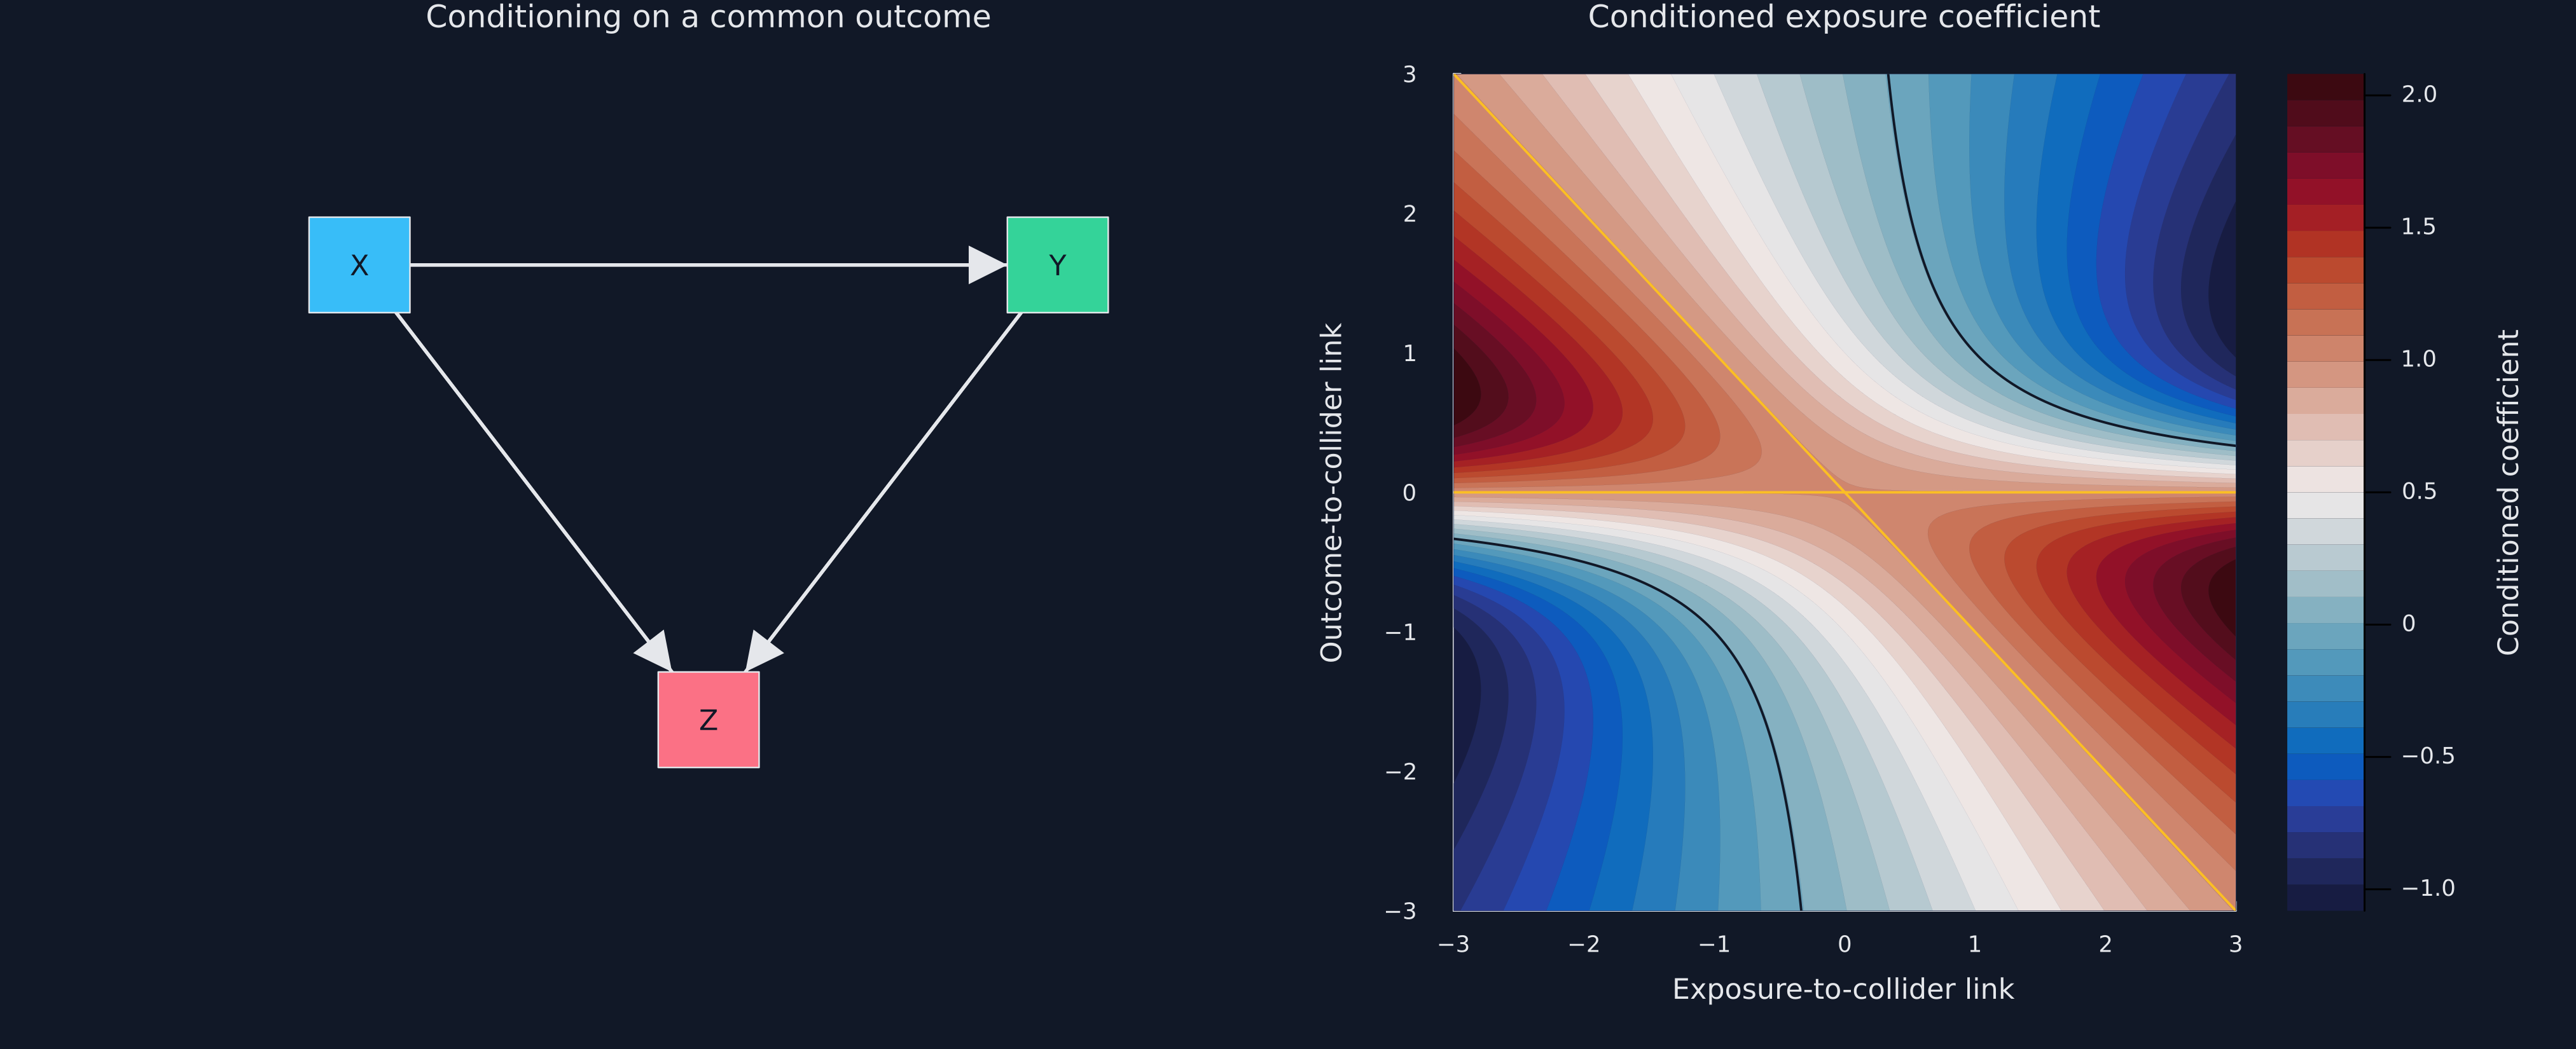

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("04_factor_mirage");
using CSV, TOML
using RiskLabAI.CausalFactorAnalysis
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy
include(joinpath("..","support","BookTreatmentStudy.jl"))
using .BookTreatmentStudy: histogram_peak
include(joinpath("..","support","BookMirageStudy.jl"))
using .BookMirageStudy
chapter_palette=(background="#111827",axes="#111827",text="#E5E7EB",cyan="#38BDF8",amber="#FBBF24",green="#34D399",rose="#FB7185",grid="#374151")
default(background_color=chapter_palette.background,background_color_inside=chapter_palette.axes,foreground_color=chapter_palette.text,gridcolor=chapter_palette.grid,fontfamily="sans-serif",left_margin=10Plots.mm,bottom_margin=10Plots.mm,titlefontsize=11,guidefontsize=10)
store=PrimitiveStore(joinpath("..","data","chapter04_random_inputs"),"mirage")
captions=Dict("confounder_standardized_coefficients"=>"Standardized omitted-confounder coefficients.","confounder_generated_check"=>"A visible fixed-seed confounder experiment.","confounder_general_variance"=>"Omitted coefficients with general positive variances.","confounder_return_examples"=>"Correct and omitted-confounder expected returns.","confounder_static_gap"=>"The exact fixed-link forecast-return gap.","confounder_zero_boundaries"=>"Exact coefficient and shifted-return sign boundaries.","confounder_input_checks"=>"Input-boundary checks for omitted-confounder calculations.","confounder_numerical_stability"=>"Finite-scaling and sign-preservation checks.","confounder_section_summary"=>"Main conclusions from the omitted-confounder experiments.","collider_standardized_coefficients"=>"Population coefficients after conditioning on the collider.","collider_generated_check"=>"A visible fixed-seed collider experiment.","collider_general_variance"=>"Collider-conditioned coefficients with general variances.","collider_return_examples"=>"Negative expected returns after collider conditioning.","collider_return_boundaries"=>"Exact equality and zero boundaries for collider returns.","collider_diagnostic_example"=>"Model-comparison quantities for the released Appendix example.","collider_adjusted_threshold"=>"The strict adjusted explained-variance threshold.","collider_expected_signals"=>"Expected coefficient signals under the population approximation.","collider_conditional_selection"=>"Marginal independence and collider-induced conditional association.","collider_input_checks"=>"Input-boundary checks for collider calculations.","collider_numerical_stability"=>"Finite-scaling and sign-preservation checks for collider calculations.","collider_section_summary"=>"Main conclusions from the collider experiments.","specification_population_targets"=>"Exact population targets for the three structural systems.","specification_seed_zero_samples"=>"Seed-zero sample diagnostics with 5,000 observations.","specification_visible_generation_parity"=>"Visible generation agrees with the released fixed-seed experiments.","specification_population_sample_gaps"=>"Population targets and seed-zero sample errors.","specification_repeated_convergence"=>"Repeated-sample convergence to the population coefficient targets.","specification_seed_variation"=>"Coefficient variation across fixed-seed generated samples.","specification_input_checks"=>"Invalid sample-size and seed checks for all three experiments.","specification_record_checks"=>"Repeatability and immutable-record checks.","specification_public_surface"=>"Released public records and functions covered by Chapter 26.","specification_section_summary"=>"How the three wrong specifications change the exposure coefficient.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:chapter26-"*replace(name,"_"=>"-"))
    return nothing
end
function assert_artifacts(figures,tables)
    @assert all(name->isfile(joinpath(paths.figures,name*".pdf")),figures)
    @assert all(name->isfile(joinpath(paths.tables,name*".tex")),tables)
end
function graph_panel(nodes,edges,positions,title)
    graph=DirectedGraph(nodes,edges)
    xs,ys=[positions[node][1] for node in graph.nodes],[positions[node][2] for node in graph.nodes]
    spanx,spany=max(maximum(xs)-minimum(xs),2.),max(maximum(ys)-minimum(ys),1.5)
    rx,ry=.065spanx,.07spany
    figure=plot(;title,legend=false,axis=false,grid=false,xlims=(minimum(xs)-.22spanx,maximum(xs)+.22spanx),ylims=(minimum(ys)-.28spany,maximum(ys)+.28spany),widen=false)
    for (left,right) in graph.edges
        x1,y1=positions[left]
        x2,y2=positions[right]
        dx,dy=x2-x1,y2-y1
        fraction=min(abs(dx)>0 ? rx/abs(dx) : Inf,abs(dy)>0 ? ry/abs(dy) : Inf,.42)
        plot!(figure,[x1+fraction*dx,x2-fraction*dx],[y1+fraction*dy,y2-fraction*dy];color=chapter_palette.text,linewidth=1.8,arrow=Plots.arrow(:closed,.14,.12),label="")
    end
    for node in graph.nodes
        x,y=positions[node]
        color=node=="X" ? chapter_palette.cyan : node=="Y" ? chapter_palette.green : node=="W" || (node=="Z" && ("Z","X") in graph.edges) ? chapter_palette.amber : chapter_palette.rose
        plot!(figure,Shape([x-rx,x+rx,x+rx,x-rx],[y-ry,y-ry,y+ry,y+ry]);fillcolor=color,linecolor=chapter_palette.text,linewidth=.8,label="")
        annotate!(figure,x,y,text(node,10,chapter_palette.background,:center))
    end
    return figure
end
standardized_cases=[(.5,1.,.8),(1.,-2.,.25),(-.7,.4,-1.2),(.7,1.5,-1.05),(.7,0.,4.)]
standardized_rows=Tuple[]
for (beta,gamma,delta) in standardized_cases
    result=collider_overcontrolled_coefficients(beta,gamma,delta)
    push!(standardized_rows,(beta,gamma,delta,result.beta_hat,result.theta_hat,result.beta_hat-beta))
end
standardized_table=frame(["Direct effect","Outcome-to-collider link","Exposure-to-collider link","Conditioned exposure coefficient","Conditioned collider coefficient","Exposure-coefficient error"],standardized_rows)
table(standardized_table,"collider_standardized_coefficients")
beta,gamma,delta=.5,1.,.8
sample_size=5000
draws=primitive_sample(store,sample_size,0)
exposure,outcome_noise,collider_noise=draws[:,1],draws[:,2],draws[:,3]
outcome=beta.*exposure+outcome_noise
collider=gamma.*outcome+delta.*exposure+collider_noise
unconditioned=manual_diagnostics(outcome,[exposure],["Exposure"])
conditioned=manual_diagnostics(outcome,[exposure,collider],["Exposure","Collider"])
population=collider_overcontrolled_coefficients(beta,gamma,delta)
generated_table=frame(["Specification","Exposure coefficient","Exposure target","Collider coefficient","Collider target","Explained variance","Observations","Seed"],[("Collider omitted",unconditioned.coefficients[2],beta,NaN,NaN,unconditioned.r_squared,sample_size,0),("Collider included",conditioned.coefficients[2],population.beta_hat,conditioned.coefficients[3],population.theta_hat,conditioned.r_squared,sample_size,0)])
table(generated_table,"collider_generated_check")
save_data(DataFrame("Exposure"=>exposure,"Outcome noise"=>outcome_noise,"Collider noise"=>collider_noise,"Outcome"=>outcome,"Collider"=>collider),paths,"collider_generated_values")
gamma_grid=collect(range(-3.,3.;length=241))
delta_grid=collect(range(-3.,3.;length=241))
coefficient_mesh=[(1-d*g)/(1+g^2) for g in gamma_grid,d in delta_grid]
graph=graph_panel(["X","Y","Z"],[("X","Y"),("X","Z"),("Y","Z")],Dict("X"=>(0.,0.),"Y"=>(1.8,0.),"Z"=>(.9,-1.)),"Conditioning on a common outcome")
surface=contourf(delta_grid,gamma_grid,coefficient_mesh;levels=31,color=:balance,linewidth=0,colorbar_title="Conditioned coefficient",xlabel="Exposure-to-collider link",ylabel="Outcome-to-collider link",title="Conditioned exposure coefficient")
contour!(surface,delta_grid,gamma_grid,coefficient_mesh;levels=[0.],color=chapter_palette.background,linewidth=1.3,colorbar_entry=false)
contour!(surface,delta_grid,gamma_grid,coefficient_mesh;levels=[1.],color=chapter_palette.amber,linewidth=1.3,colorbar_entry=false)
save_figure(plot(graph,surface;layout=(1,2),size=(1350,550)),paths,"collider_graph_and_coefficient")
save_data(frame(["Outcome link","Exposure link","Conditioned exposure coefficient"],[(g,d,coefficient_mesh[i,j]) for (i,g) in enumerate(gamma_grid) for (j,d) in enumerate(delta_grid)]),paths,"collider_coefficient_surface");


## General disturbance variances

With general positive disturbance variances, the conditioned coefficients become:

$$
\widehat\beta
=\frac{\beta\sigma_V^2-\delta\gamma\sigma_U^2}
{\sigma_V^2+\gamma^2\sigma_U^2},
\qquad
\widehat\theta
=\frac{\gamma\sigma_U^2}
{\sigma_V^2+\gamma^2\sigma_U^2}.
$$

Here, $\sigma_U^2=\operatorname{Var}(U)$ is the outcome-disturbance variance, $\sigma_V^2=\operatorname{Var}(V)$ is the collider-disturbance variance, and the remaining symbols retain their meanings from the collider system; both variances must be strictly positive.

Row,Case,Direct effect,Outcome link,Exposure link,Outcome-noise variance,Collider-noise variance,Exposure coefficient,Collider coefficient
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,Unequal variances,0.8,1.2,-0.4,2.0,3.0,0.571429,0.408163
2,Small outcome disturbance,-0.5,0.75,2.0,0.25,4.0,-0.573585,0.045283
3,Large outcome disturbance,2.0,-1.0,-0.25,3.5,0.5,0.03125,-0.875
4,No outcome-to-collider link,1.25,0.0,7.0,5.0,2.0,1.25,0.0
5,Unit variances,0.5,1.0,0.8,1.0,1.0,-0.15,0.5


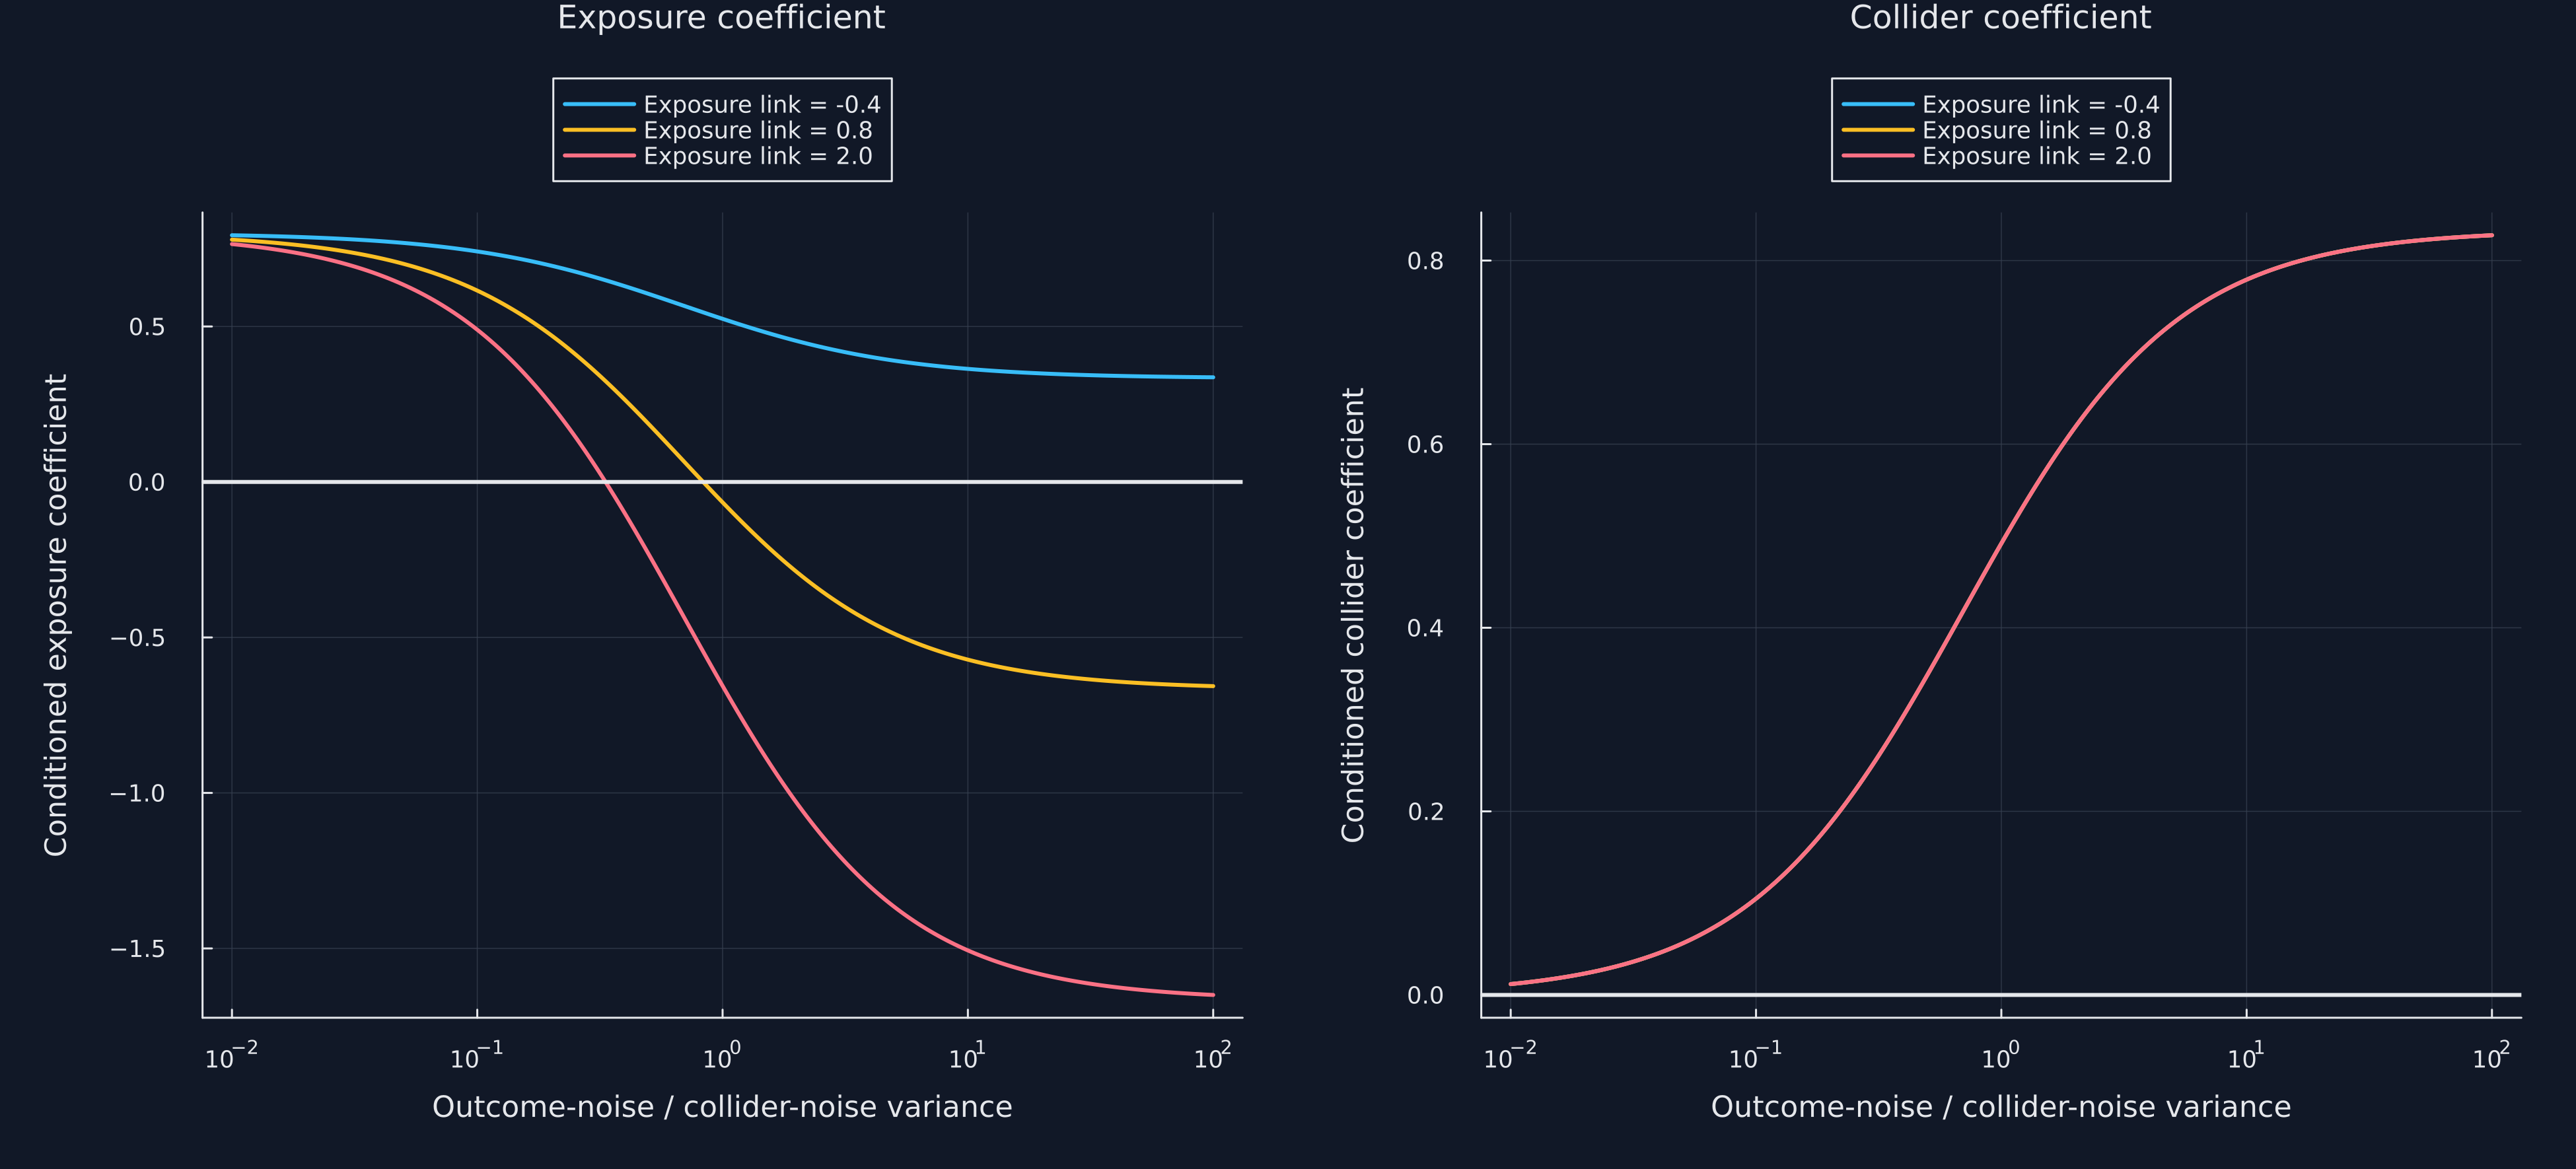

In [2]:
variance_cases=[("Unequal variances",.8,1.2,-.4,2.,3.),("Small outcome disturbance",-.5,.75,2.,.25,4.),("Large outcome disturbance",2.,-1.,-.25,3.5,.5),("No outcome-to-collider link",1.25,0.,7.,5.,2.),("Unit variances",.5,1.,.8,1.,1.)]
variance_rows=Tuple[]
for (name,beta,gamma,delta,outcome_variance,collider_variance) in variance_cases
    result=generalized_collider_overcontrolled_coefficients(beta,gamma,delta;outcome_noise_variance=outcome_variance,collider_noise_variance=collider_variance)
    push!(variance_rows,(name,beta,gamma,delta,outcome_variance,collider_variance,result.beta_hat,result.theta_hat))
end
variance_table=frame(["Case","Direct effect","Outcome link","Exposure link","Outcome-noise variance","Collider-noise variance","Exposure coefficient","Collider coefficient"],variance_rows)
table(variance_table,"collider_general_variance")
variance_ratios=10.0 .^collect(range(-2.,2.;length=240))
variance_paths=Tuple[]
panels=[plot(;xscale=:log10,xlabel="Outcome-noise / collider-noise variance",ylabel="Conditioned "*name*" coefficient",title=title,legend=:outertop) for (name,title) in [("exposure","Exposure coefficient"),("collider","Collider coefficient")]]
for (link,color) in [(-.4,chapter_palette.cyan),(.8,chapter_palette.amber),(2.,chapter_palette.rose)]
    results=[generalized_collider_overcontrolled_coefficients(.8,1.2,link;outcome_noise_variance=ratio,collider_noise_variance=1.) for ratio in variance_ratios]
    plot!(panels[1],variance_ratios,getproperty.(results,:beta_hat);color,linewidth=2,label="Exposure link = "*string(link))
    plot!(panels[2],variance_ratios,getproperty.(results,:theta_hat);color,linewidth=2,label="Exposure link = "*string(link))
    append!(variance_paths,[(link,ratio,result.beta_hat,result.theta_hat) for (ratio,result) in zip(variance_ratios,results)])
end
for panel in panels
    hline!(panel,[0.];color=chapter_palette.text,label="")
end
save_figure(plot(panels...;layout=(1,2),size=(1300,590)),paths,"collider_variance_ratio")
save_data(frame(["Exposure link","Variance ratio","Exposure coefficient","Collider coefficient"],variance_paths),paths,"collider_variance_paths");


## A proxy available before the outcome

The factor and forecast returns from the correct and collider-conditioned rules are:

$$
\begin{aligned}
R_C(x)&=(\beta x)^2,
&R_O(x,\widetilde z)&=\frac{\beta x\{(\beta-\delta\gamma)x+\gamma\widetilde z\}}{1+\gamma^2},\\
F_C&=\beta^2,
&F_O&=\frac{\beta(\beta-\gamma\delta)}{1+\gamma^2}.
\end{aligned}
$$

Here, $R_C$ and $R_O$ are conditional factor returns, $F_C$ and $F_O$ are forecast returns after averaging over the exposure distribution, $x$ is the exposure value, and $\widetilde z$ is a proxy observed before the outcome; it is not the contemporaneous collider $Z$, which already contains $Y$.

Row,Target,Exposure,Pre-outcome proxy,Direct effect,Outcome link,Exposure link,Correct return,Misspecified return
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,Factor return,1.0,1.0,1.0,1.0,3.0,1.0,-0.5
2,Forecast return,NaN,NaN,1.0,1.0,2.0,1.0,-0.5


Row,Boundary,Correct return,Misspecified return
,String,Float64,Float64
1,Zero direct effect,0.0,0.0
2,Direct effect equals link product,4.0,0.0
3,Zero outcome-to-collider link,0.36,0.36
4,Zero exposure,0.0,0.0


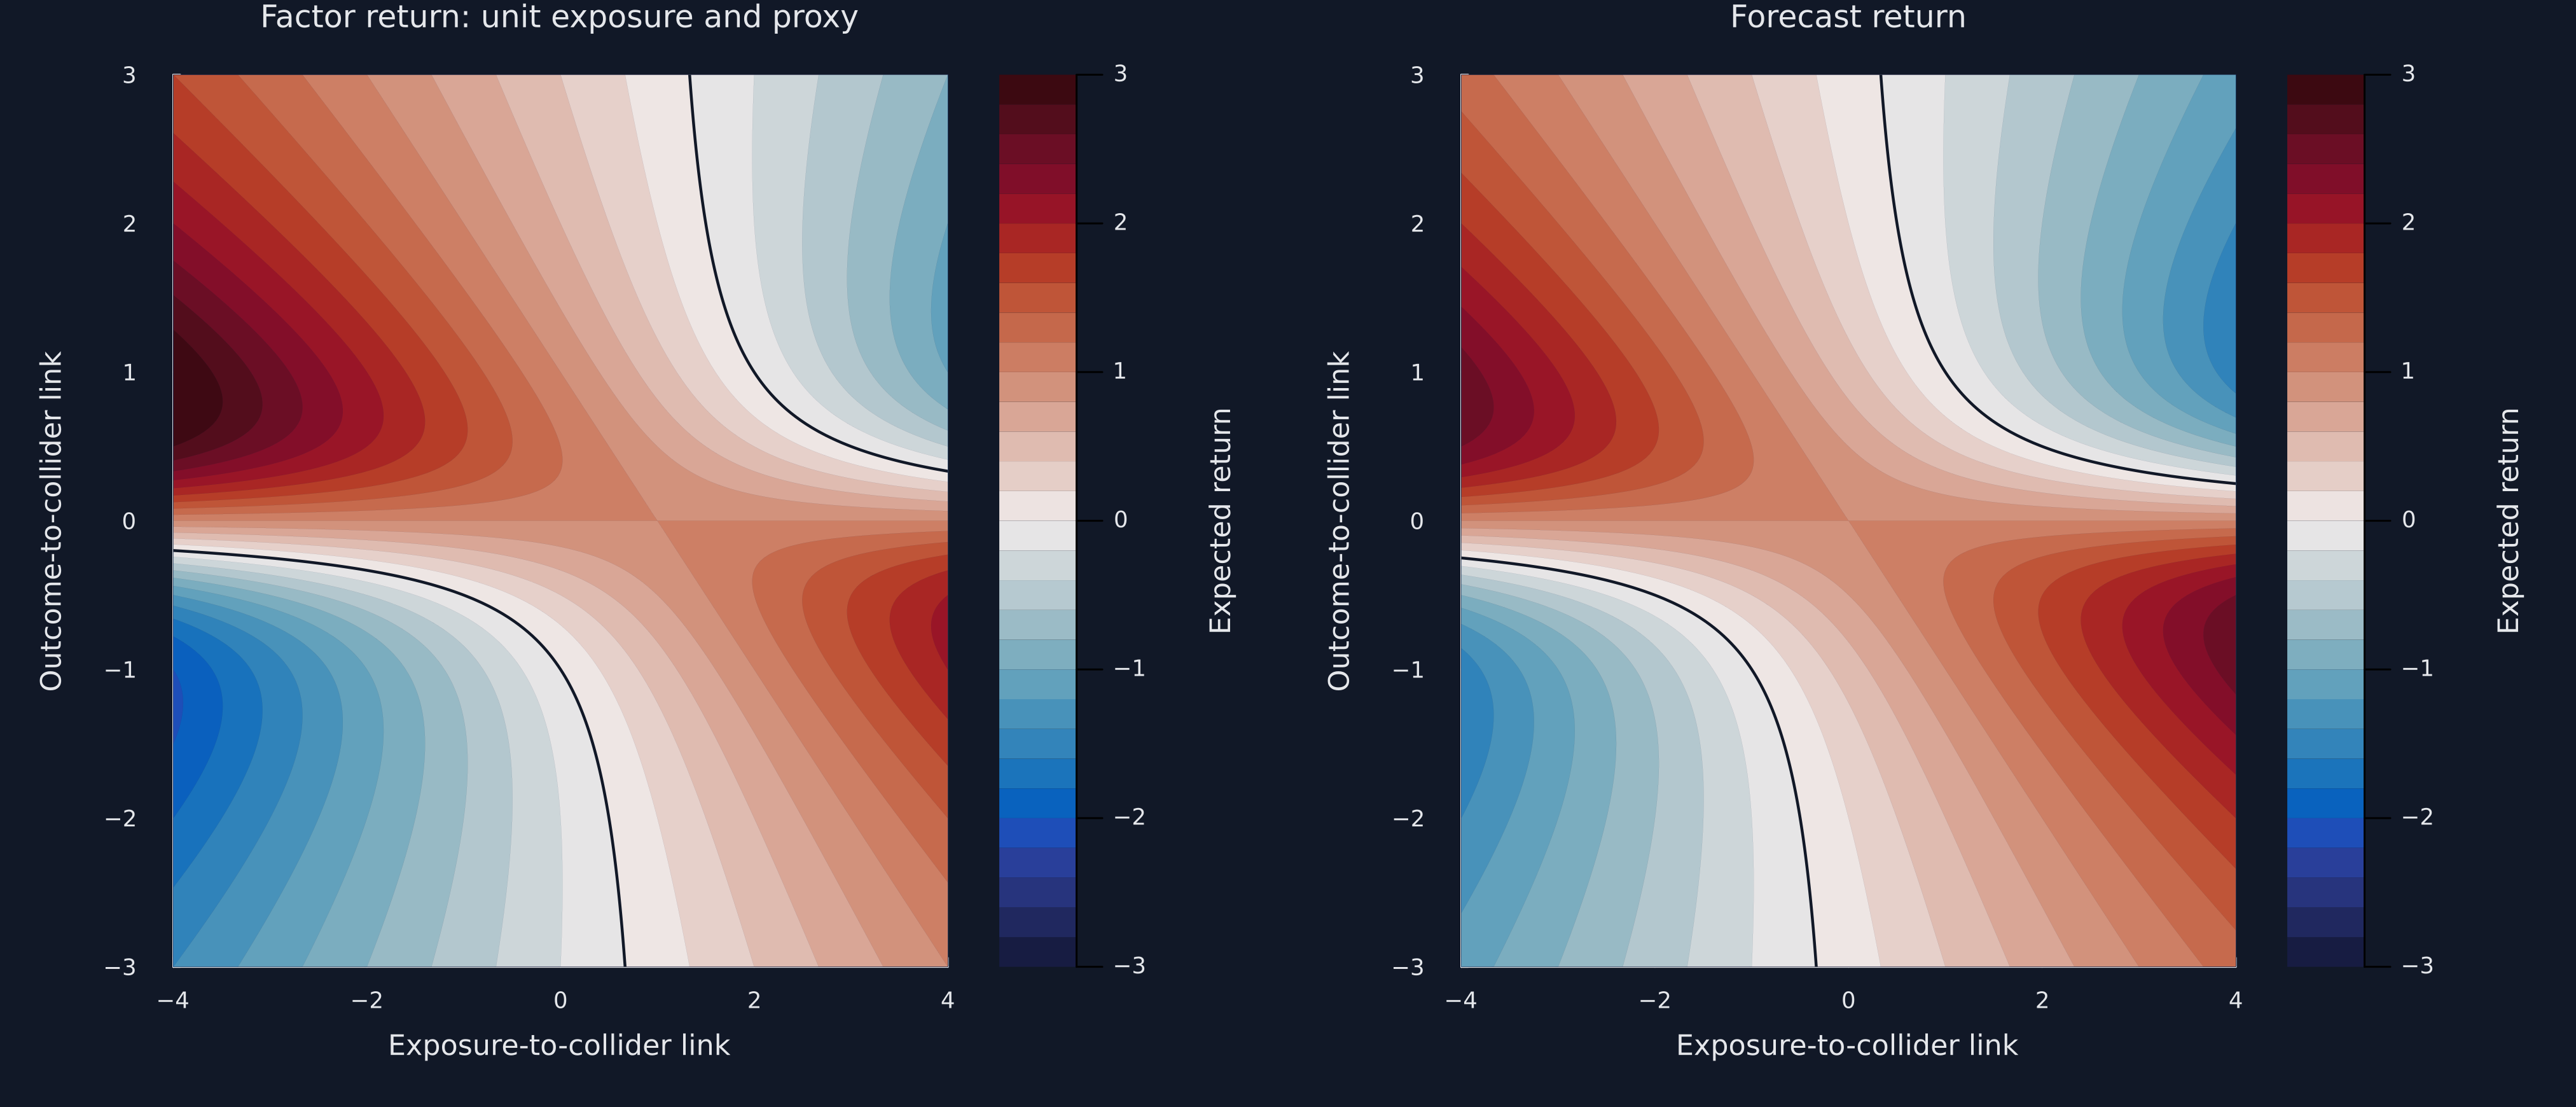

In [3]:
factor_example=collider_factor_return(1.,1.,1.,1.,3.)
forecast_example=collider_forecast_return(1.,1.,2.)
return_table=frame(["Target","Exposure","Pre-outcome proxy","Direct effect","Outcome link","Exposure link","Correct return","Misspecified return"],[("Factor return",1.,1.,1.,1.,3.,factor_example.correct,factor_example.misspecified),("Forecast return",NaN,NaN,1.,1.,2.,forecast_example.correct,forecast_example.misspecified)])
table(return_table,"collider_return_examples")
boundary_table=frame(["Boundary","Correct return","Misspecified return"],[(name,result.correct,result.misspecified) for (name,result) in [("Zero direct effect",collider_forecast_return(0.,2.,3.)),("Direct effect equals link product",collider_forecast_return(2.,1.,2.)),("Zero outcome-to-collider link",collider_forecast_return(.6,0.,3.)),("Zero exposure",collider_factor_return(0.,4.,1.,2.,3.))]])
table(boundary_table,"collider_return_boundaries")
gamma_values=collect(range(-3.,3.;length=241))
delta_values=collect(range(-4.,4.;length=281))
forecast_mesh=[(1-g*d)/(1+g^2) for g in gamma_values,d in delta_values]
factor_mesh=[((1-d*g)+g)/(1+g^2) for g in gamma_values,d in delta_values]
panels=Plots.Plot[]
for (values,title) in [(factor_mesh,"Factor return: unit exposure and proxy"),(forecast_mesh,"Forecast return")]
    panel=contourf(delta_values,gamma_values,values;levels=collect(range(-3.,3.;length=31)),clims=(-3,3),color=:balance,linewidth=0,colorbar_title="Expected return",xlabel="Exposure-to-collider link",ylabel="Outcome-to-collider link",title)
    contour!(panel,delta_values,gamma_values,values;levels=[0.],color=chapter_palette.background,linewidth=1.5,colorbar_entry=false)
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(1,2),size=(1350,580)),paths,"collider_return_regions")
save_data(frame(["Outcome link","Exposure link","Factor return","Forecast return"],[(g,d,factor_mesh[i,j],forecast_mesh[i,j]) for (i,g) in enumerate(gamma_values) for (j,d) in enumerate(delta_values)]),paths,"collider_return_surfaces");


## Comparing fit after collider adjustment

In the standardized system, explained variance and its adjusted comparison satisfy:

$$
R_C^2=1-\frac{1}{1+\beta^2},
\qquad
R_O^2=1-\frac{1}{(1+\gamma^2)(1+\beta^2)},
\qquad
\overline R_O^2>\overline R_C^2
\Longleftrightarrow
|\gamma|>\frac{1}{\sqrt{n-3}}.
$$

Here, $R_C^2$ and $R_O^2$ are ordinary explained-variance fractions for the correct and overcontrolled regressions, $\overline R_C^2$ and $\overline R_O^2$ are their adjusted versions, $\gamma$ is the outcome-to-collider link, and $n$ is the sample size, which must exceed three.

Row,Quantity,Value
,String,Float64
1,Residual variance after conditioning,0.5
2,Outcome variance,2.0
3,Correct explained variance,0.5
4,Overcontrolled explained variance,0.75
5,Correct adjusted explained variance,0.333333
6,Overcontrolled adjusted explained variance,0.5
7,Correct exposure-coefficient variance,0.2
8,Overcontrolled exposure-coefficient variance,0.55
9,Collider-coefficient variance,0.05


Row,Observations,Position,Outcome link,Strict threshold,Correct adjusted explained variance,Overcontrolled adjusted explained variance,Overcontrolled preferred
,Int64,String,Float64,Float64,Float64,Float64,String
1,7,Below,0.49,0.5,0.4,0.39521,No
2,7,At,0.5,0.5,0.4,0.4,No
3,7,Above,0.51,0.5,0.4,0.404809,Yes
4,19,Below,0.245,0.25,0.470588,0.469352,No
5,19,At,0.25,0.25,0.470588,0.470588,No
6,19,Above,0.255,0.25,0.470588,0.471843,Yes
7,67,Below,0.1225,0.125,0.492308,0.491998,No
8,67,At,0.125,0.125,0.492308,0.492308,No
9,67,Above,0.1275,0.125,0.492308,0.492623,Yes


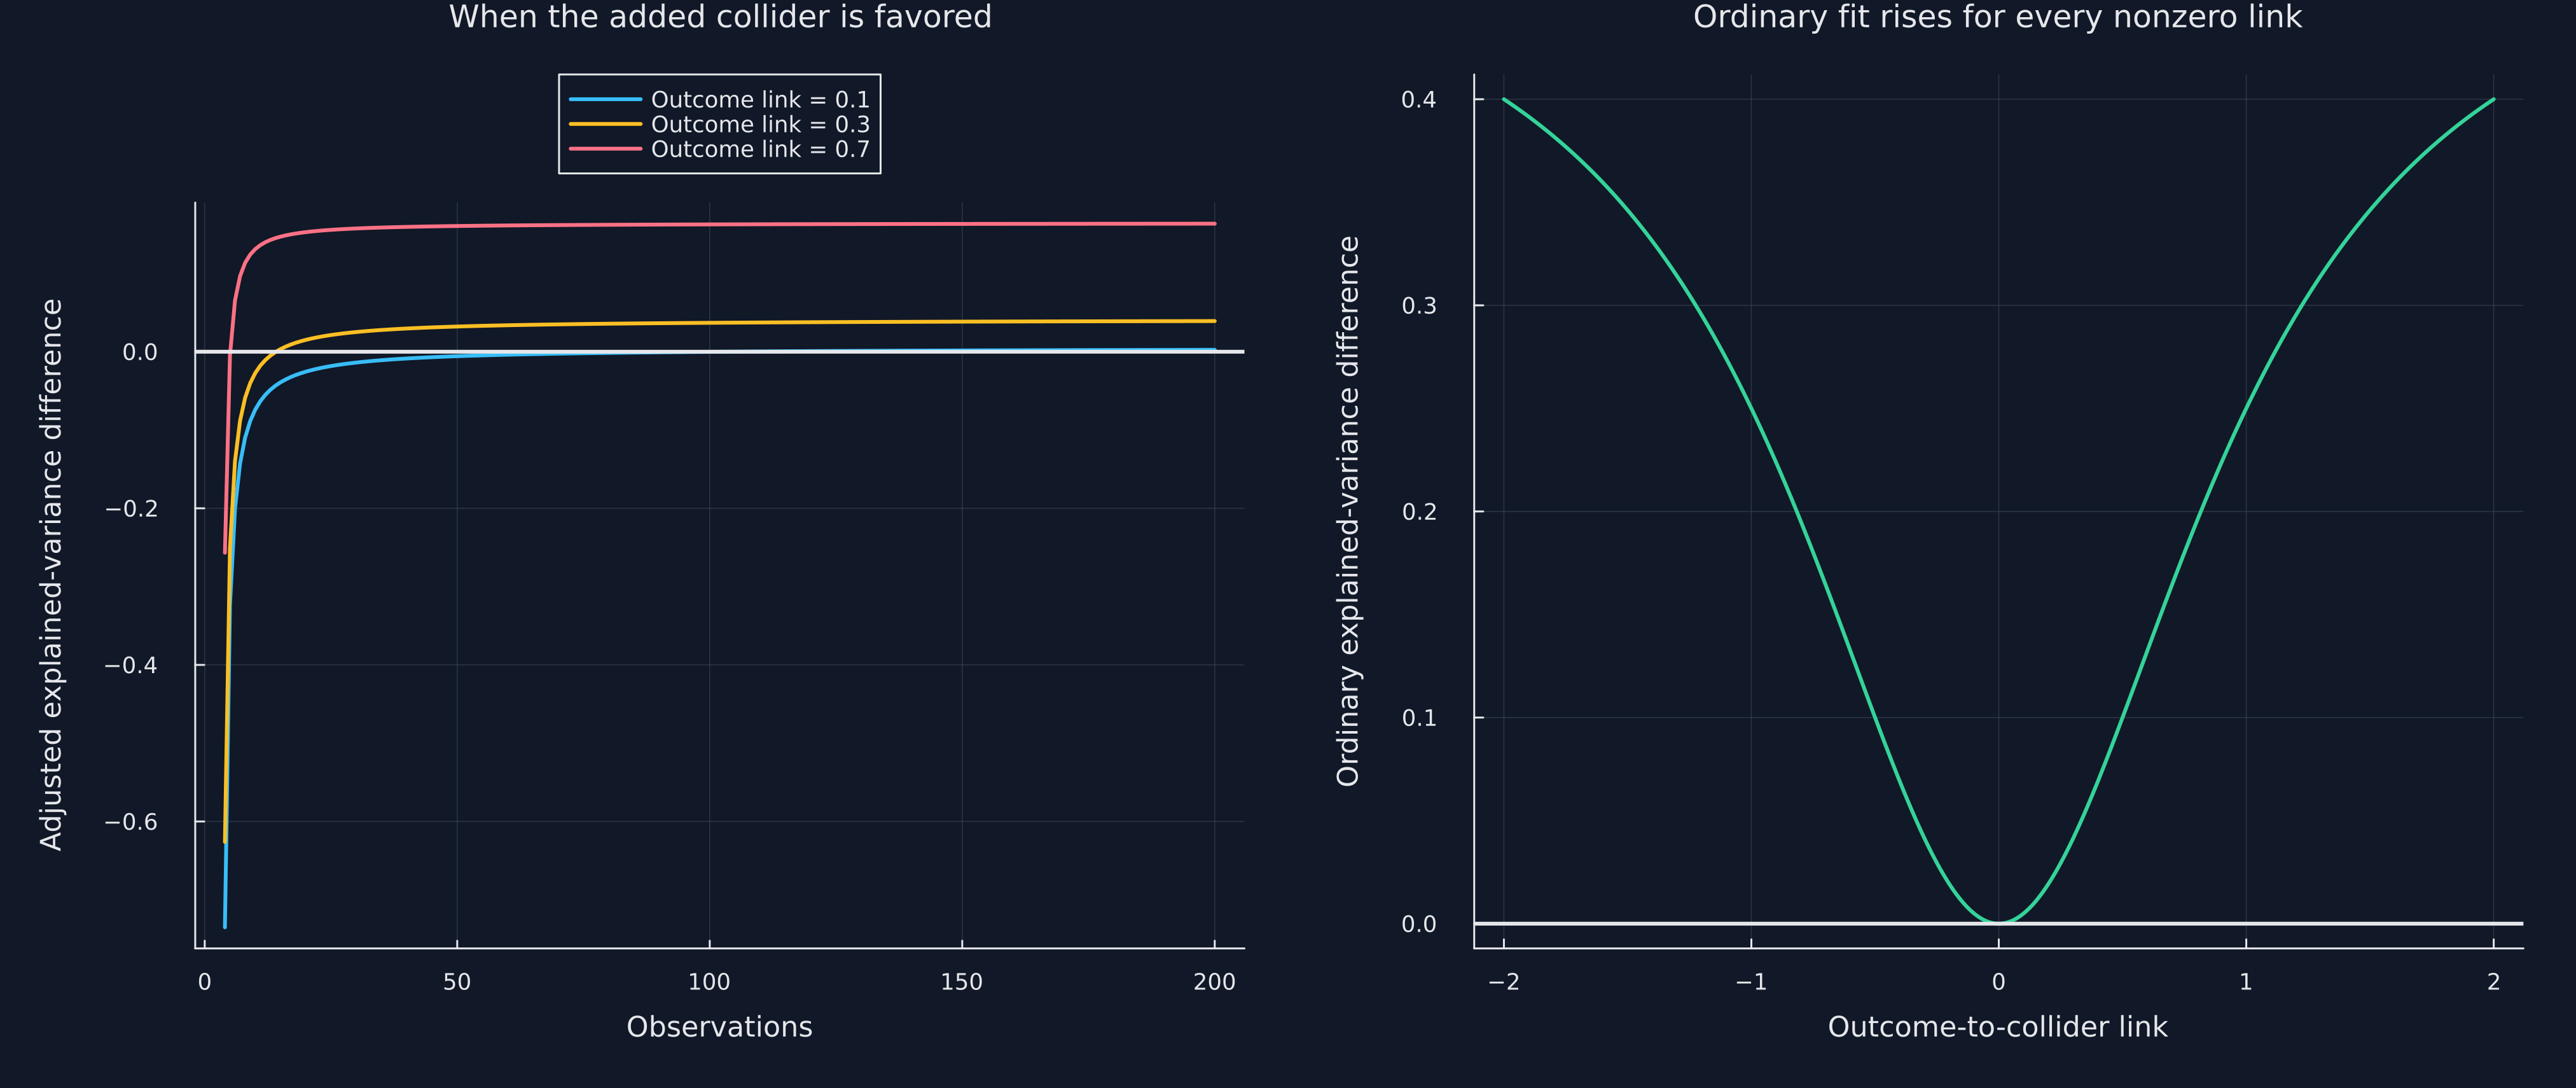

In [4]:
diagnostics=collider_model_diagnostics(1.,1.,2.,5)
diagnostics_table=frame(["Quantity","Value"],[("Residual variance after conditioning",diagnostics.residual_variance),("Outcome variance",diagnostics.outcome_variance),("Correct explained variance",diagnostics.correct_r_squared),("Overcontrolled explained variance",diagnostics.overcontrolled_r_squared),("Correct adjusted explained variance",diagnostics.correct_adjusted_r_squared),("Overcontrolled adjusted explained variance",diagnostics.overcontrolled_adjusted_r_squared),("Correct exposure-coefficient variance",diagnostics.correct_beta_variance),("Overcontrolled exposure-coefficient variance",diagnostics.overcontrolled_beta_variance),("Collider-coefficient variance",diagnostics.collider_coefficient_variance)])
table(diagnostics_table,"collider_diagnostic_example")
threshold_rows=Tuple[]
for observations in [7,19,67,259,1027]
    threshold=1/sqrt(observations-3)
    for (position,link) in [("Below",threshold*.98),("At",threshold),("Above",threshold*1.02)]
        result=collider_model_diagnostics(1.,link,0.,observations)
        push!(threshold_rows,(observations,position,link,threshold,result.correct_adjusted_r_squared,result.overcontrolled_adjusted_r_squared,result.adjusted_r_squared_prefers_overcontrolled))
    end
end
threshold_table=frame(["Observations","Position","Outcome link","Strict threshold","Correct adjusted explained variance","Overcontrolled adjusted explained variance","Overcontrolled preferred"],threshold_rows)
table(threshold_table,"collider_adjusted_threshold")
sample_sizes=collect(4:200)
fit_paths=Tuple[]
adjusted_panel=plot(;xlabel="Observations",ylabel="Adjusted explained-variance difference",title="When the added collider is favored",legend=:outertop)
for (link,color) in [(.1,chapter_palette.cyan),(.3,chapter_palette.amber),(.7,chapter_palette.rose)]
    differences=Float64[]
    for observations in sample_sizes
        result=collider_model_diagnostics(1.,link,0.,observations)
        push!(differences,result.overcontrolled_adjusted_r_squared-result.correct_adjusted_r_squared)
        push!(fit_paths,(link,observations,last(differences)))
    end
    plot!(adjusted_panel,sample_sizes,differences;color,linewidth=2,label="Outcome link = "*string(link))
end
hline!(adjusted_panel,[0.];color=chapter_palette.text,label="")
gamma_line=collect(range(-2.,2.;length=401))
ordinary_gap=[let result=collider_model_diagnostics(1.,link,0.,50);result.overcontrolled_r_squared-result.correct_r_squared end for link in gamma_line]
ordinary_panel=plot(gamma_line,ordinary_gap;color=chapter_palette.green,linewidth=2,label="",xlabel="Outcome-to-collider link",ylabel="Ordinary explained-variance difference",title="Ordinary fit rises for every nonzero link")
hline!(ordinary_panel,[0.];color=chapter_palette.text,label="")
save_figure(plot(adjusted_panel,ordinary_panel;layout=(1,2),size=(1350,570)),paths,"collider_fit_thresholds")
save_data(frame(["Outcome link","Observations","Adjusted fit difference"],fit_paths),paths,"collider_adjusted_fit_paths")
save_data(DataFrame("Outcome link"=>gamma_line,"Ordinary fit difference"=>ordinary_gap),paths,"collider_ordinary_fit_path");


## Expected coefficient test signals

The population approximation gives the following expected coefficient signals:

$$
t_C=\sqrt n\,\beta,
\qquad
t_O=\frac{\sqrt n(\beta-\delta\gamma)}{\sqrt{(\beta\gamma+\delta)^2+\gamma^2+1}},
\qquad
t_Z=\sqrt n\,\gamma.
$$

Here, $t_C$ is the expected exposure signal in the correct regression, $t_O$ is the expected exposure signal after adding the collider, $t_Z$ is the expected collider-coefficient signal, and $n$, $\beta$, $\gamma$, and $\delta$ retain their earlier meanings; these are expected signals under the stated approximation, not exact p-values.

Row,Direct effect,Outcome link,Exposure link,Observations,Correct exposure signal,Overcontrolled exposure signal,Collider signal,Larger absolute exposure signal after conditioning
,Float64,Float64,Float64,Int64,Float64,Float64,Float64,String
1,0.3,0.8,-0.2,20,1.34164,1.60561,3.57771,Yes
2,-1.0,1.5,0.4,100,-10.0,-7.57622,15.0,No
3,0.0,-2.0,3.0,8,0.0,4.53557,-5.65685,Yes
4,1.0,1.0,2.0,5,2.23607,-0.6742,2.23607,No


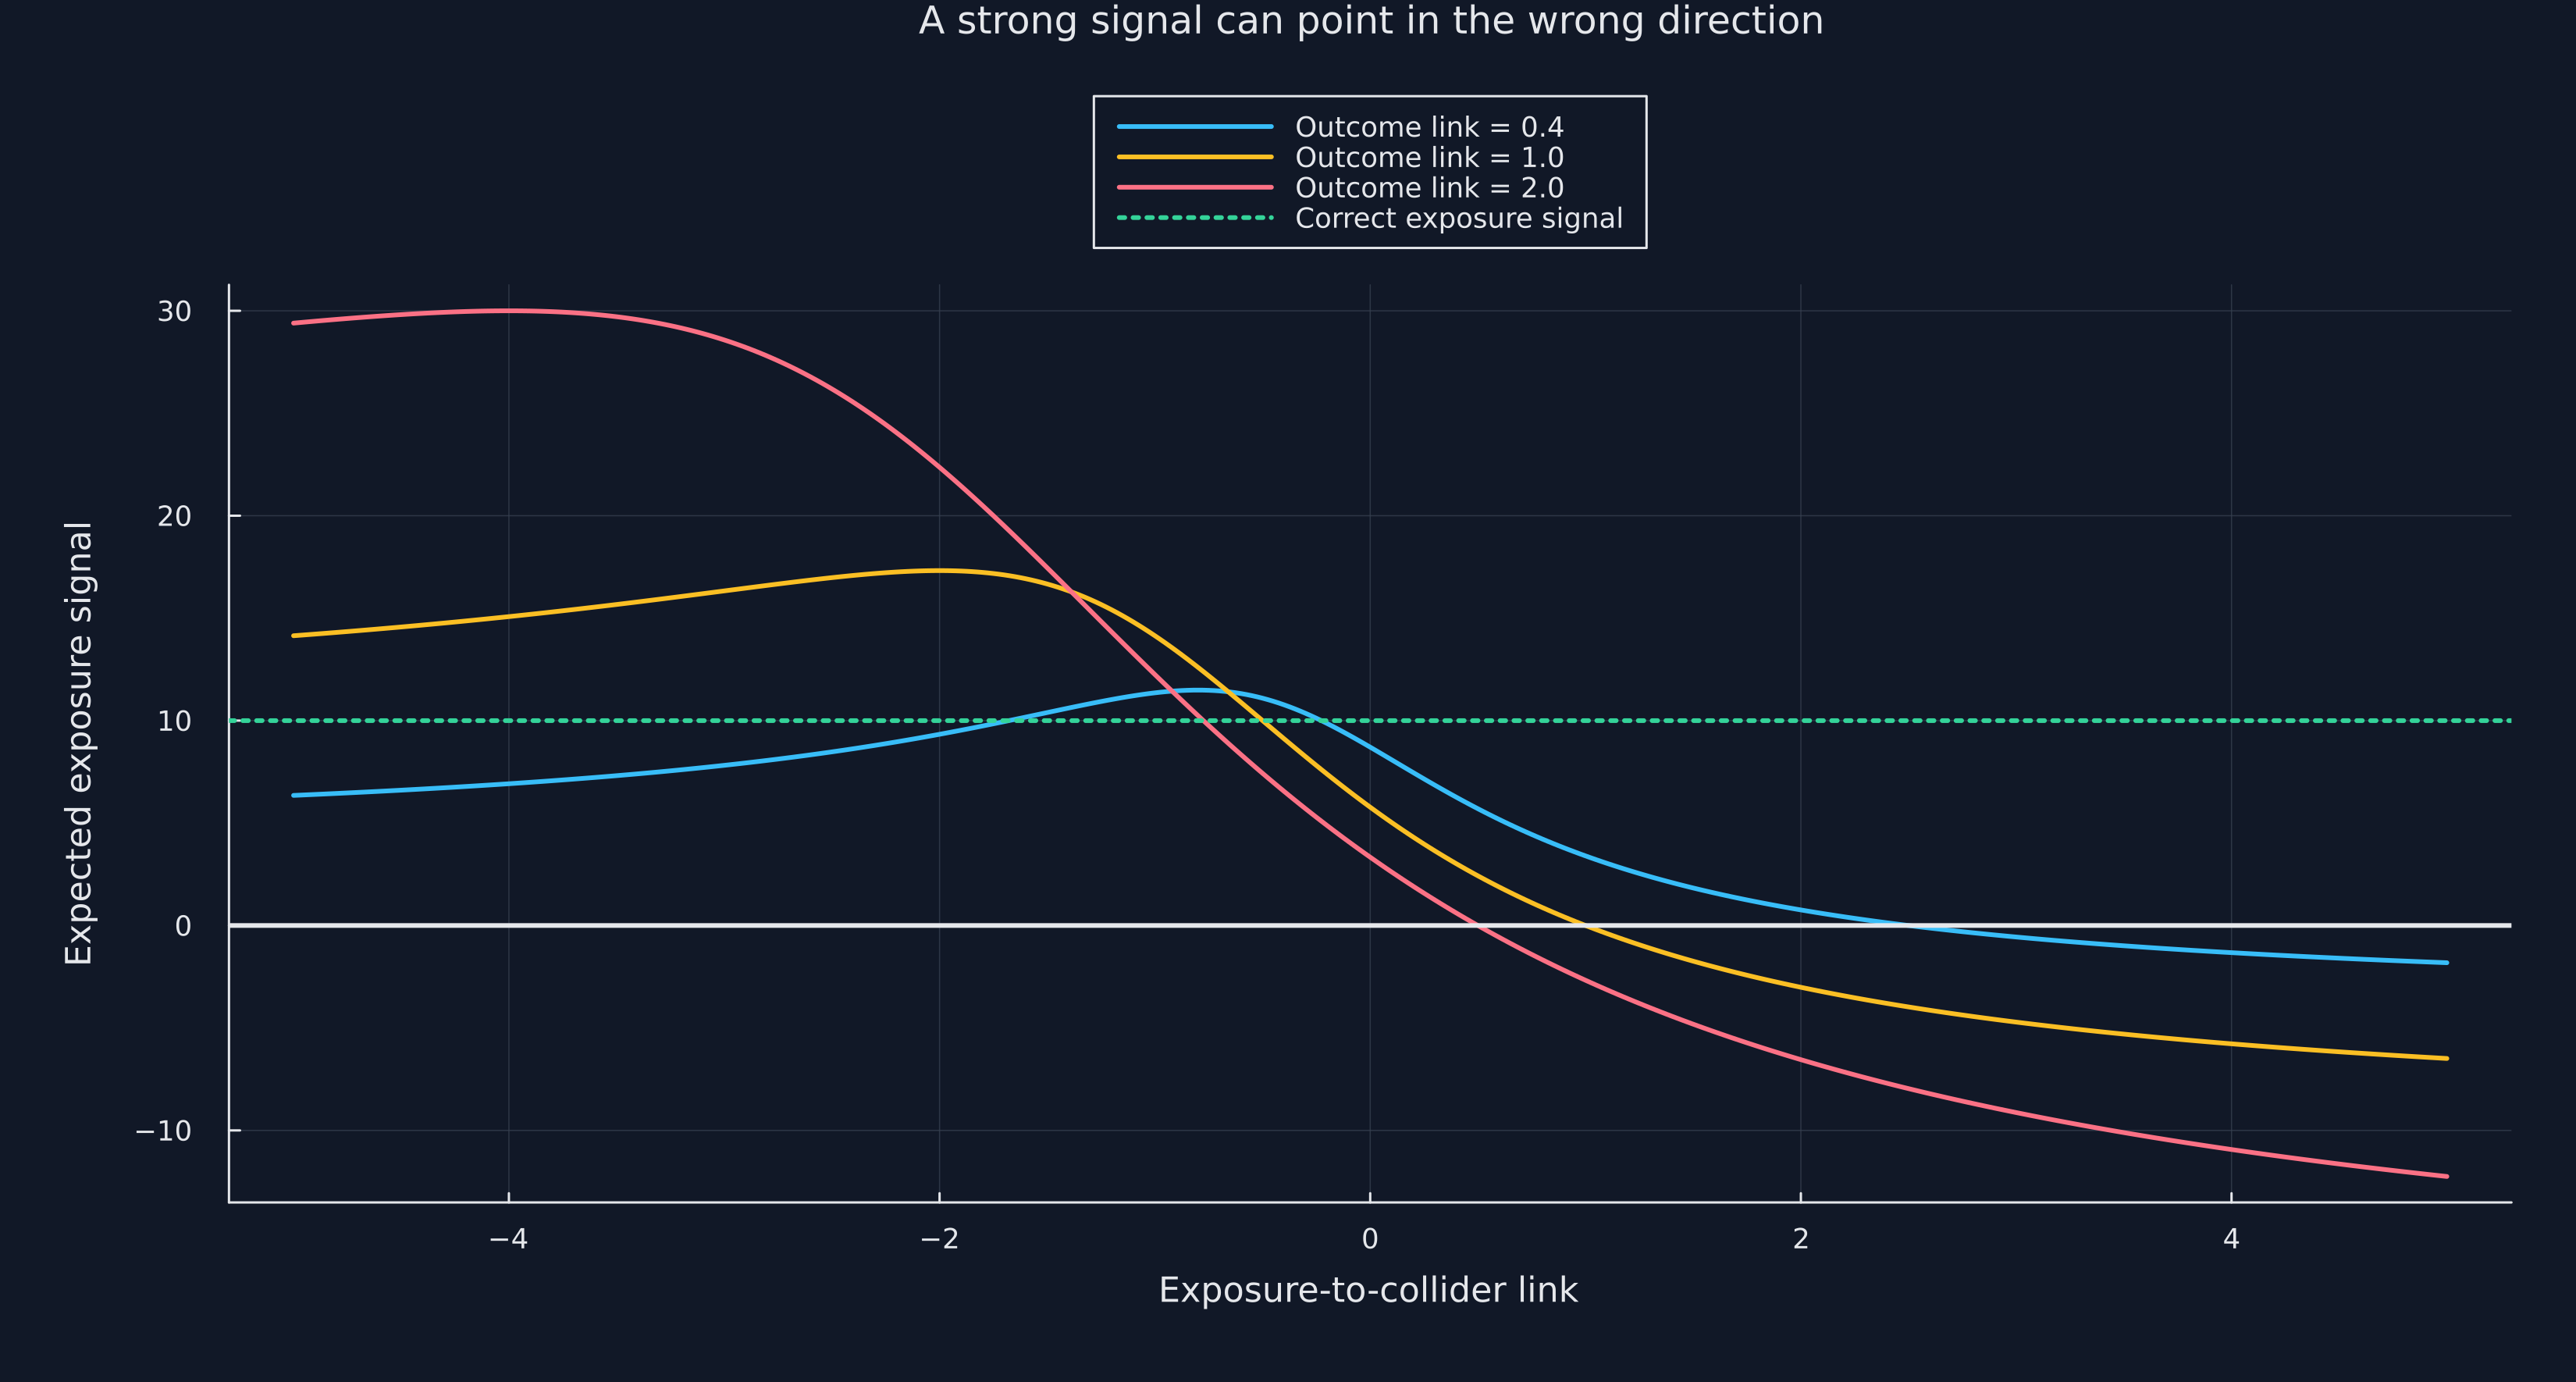

In [5]:
signal_cases=[(.3,.8,-.2,20),(-1.,1.5,.4,100),(0.,-2.,3.,8),(1.,1.,2.,5)]
signal_rows=Tuple[]
for (beta,gamma,delta,observations) in signal_cases
    result=collider_model_diagnostics(beta,gamma,delta,observations)
    push!(signal_rows,(beta,gamma,delta,observations,result.correct_beta_t_statistic,result.overcontrolled_beta_t_statistic,result.collider_t_statistic,result.absolute_beta_t_prefers_overcontrolled))
end
signal_table=frame(["Direct effect","Outcome link","Exposure link","Observations","Correct exposure signal","Overcontrolled exposure signal","Collider signal","Larger absolute exposure signal after conditioning"],signal_rows)
table(signal_table,"collider_expected_signals")
delta_line=collect(range(-5.,5.;length=401))
signal_paths=Tuple[]
figure=plot(;xlabel="Exposure-to-collider link",ylabel="Expected exposure signal",title="A strong signal can point in the wrong direction",legend=:outertop,size=(1100,590))
for (link,color) in [(.4,chapter_palette.cyan),(1.,chapter_palette.amber),(2.,chapter_palette.rose)]
    signals=[collider_model_diagnostics(1.,link,delta,100).overcontrolled_beta_t_statistic for delta in delta_line]
    plot!(figure,delta_line,signals;color,linewidth=2,label="Outcome link = "*string(link))
    append!(signal_paths,[(link,delta,value) for (delta,value) in zip(delta_line,signals)])
end
hline!(figure,[10.];color=chapter_palette.green,linestyle=:dot,label="Correct exposure signal")
hline!(figure,[0.];color=chapter_palette.text,label="")
save_figure(figure,paths,"collider_expected_signal_paths")
save_data(frame(["Outcome link","Exposure link","Expected exposure signal"],signal_paths),paths,"collider_signal_paths");


## Checking selection inputs at their boundaries

In the simple collider system $Z=X+Y+V$ with independent unit-variance inputs, conditioning creates the covariance:

$$
\operatorname{Cov}(X,Y\mid Z)
=\operatorname{Cov}(X,Y)
-\frac{\operatorname{Cov}(X,Z)\operatorname{Cov}(Z,Y)}{\operatorname{Var}(Z)}
=-\frac{1}{3}.
$$

Here, $X$ and $Y$ are marginally independent causes of the collider $Z$, $V$ is the collider disturbance, and the negative conditional covariance is created by holding their common outcome fixed.

Row,Specification,Exposure coefficient,Population target,Collider coefficient,Explained variance
,String,Float64,Float64,Float64,Float64
1,Collider omitted,0.00150355,0.0,NaN,2.24052e-6
2,Collider included,-0.496296,-0.5,0.498828,0.499189
3,Conditional covariance identity,-0.333333,-0.333333,NaN,NaN


Row,Check,Expected result,Observed result,Passed
,String,String,String,String
1,Boolean observation count,Rejected,Rejected,Yes
2,Noninteger observation count,Rejected,Rejected,Yes
3,Too few observations,Rejected,Rejected,Yes
4,Boolean coefficient,Rejected,Rejected,Yes
5,Nonfinite coefficient,Rejected,Rejected,Yes
6,Zero outcome-noise variance,Rejected,Rejected,Yes
7,Negative collider-noise variance,Rejected,Rejected,Yes
8,Required variance arguments omitted,Rejected,Rejected,Yes


Row,Check,Value,Expected value,Passed
,String,Float64,Float64,String
1,Large-link exposure coefficient,-1.0e-308,-1.0e-308,Yes
2,Large-link collider coefficient,1.0e-308,1.0e-308,Yes
3,Representable coefficient variance,2.5e-93,2.5e-93,Yes
4,Negative sign survives near cancellation,-3.64322e-17,-3.64322e-17,Yes


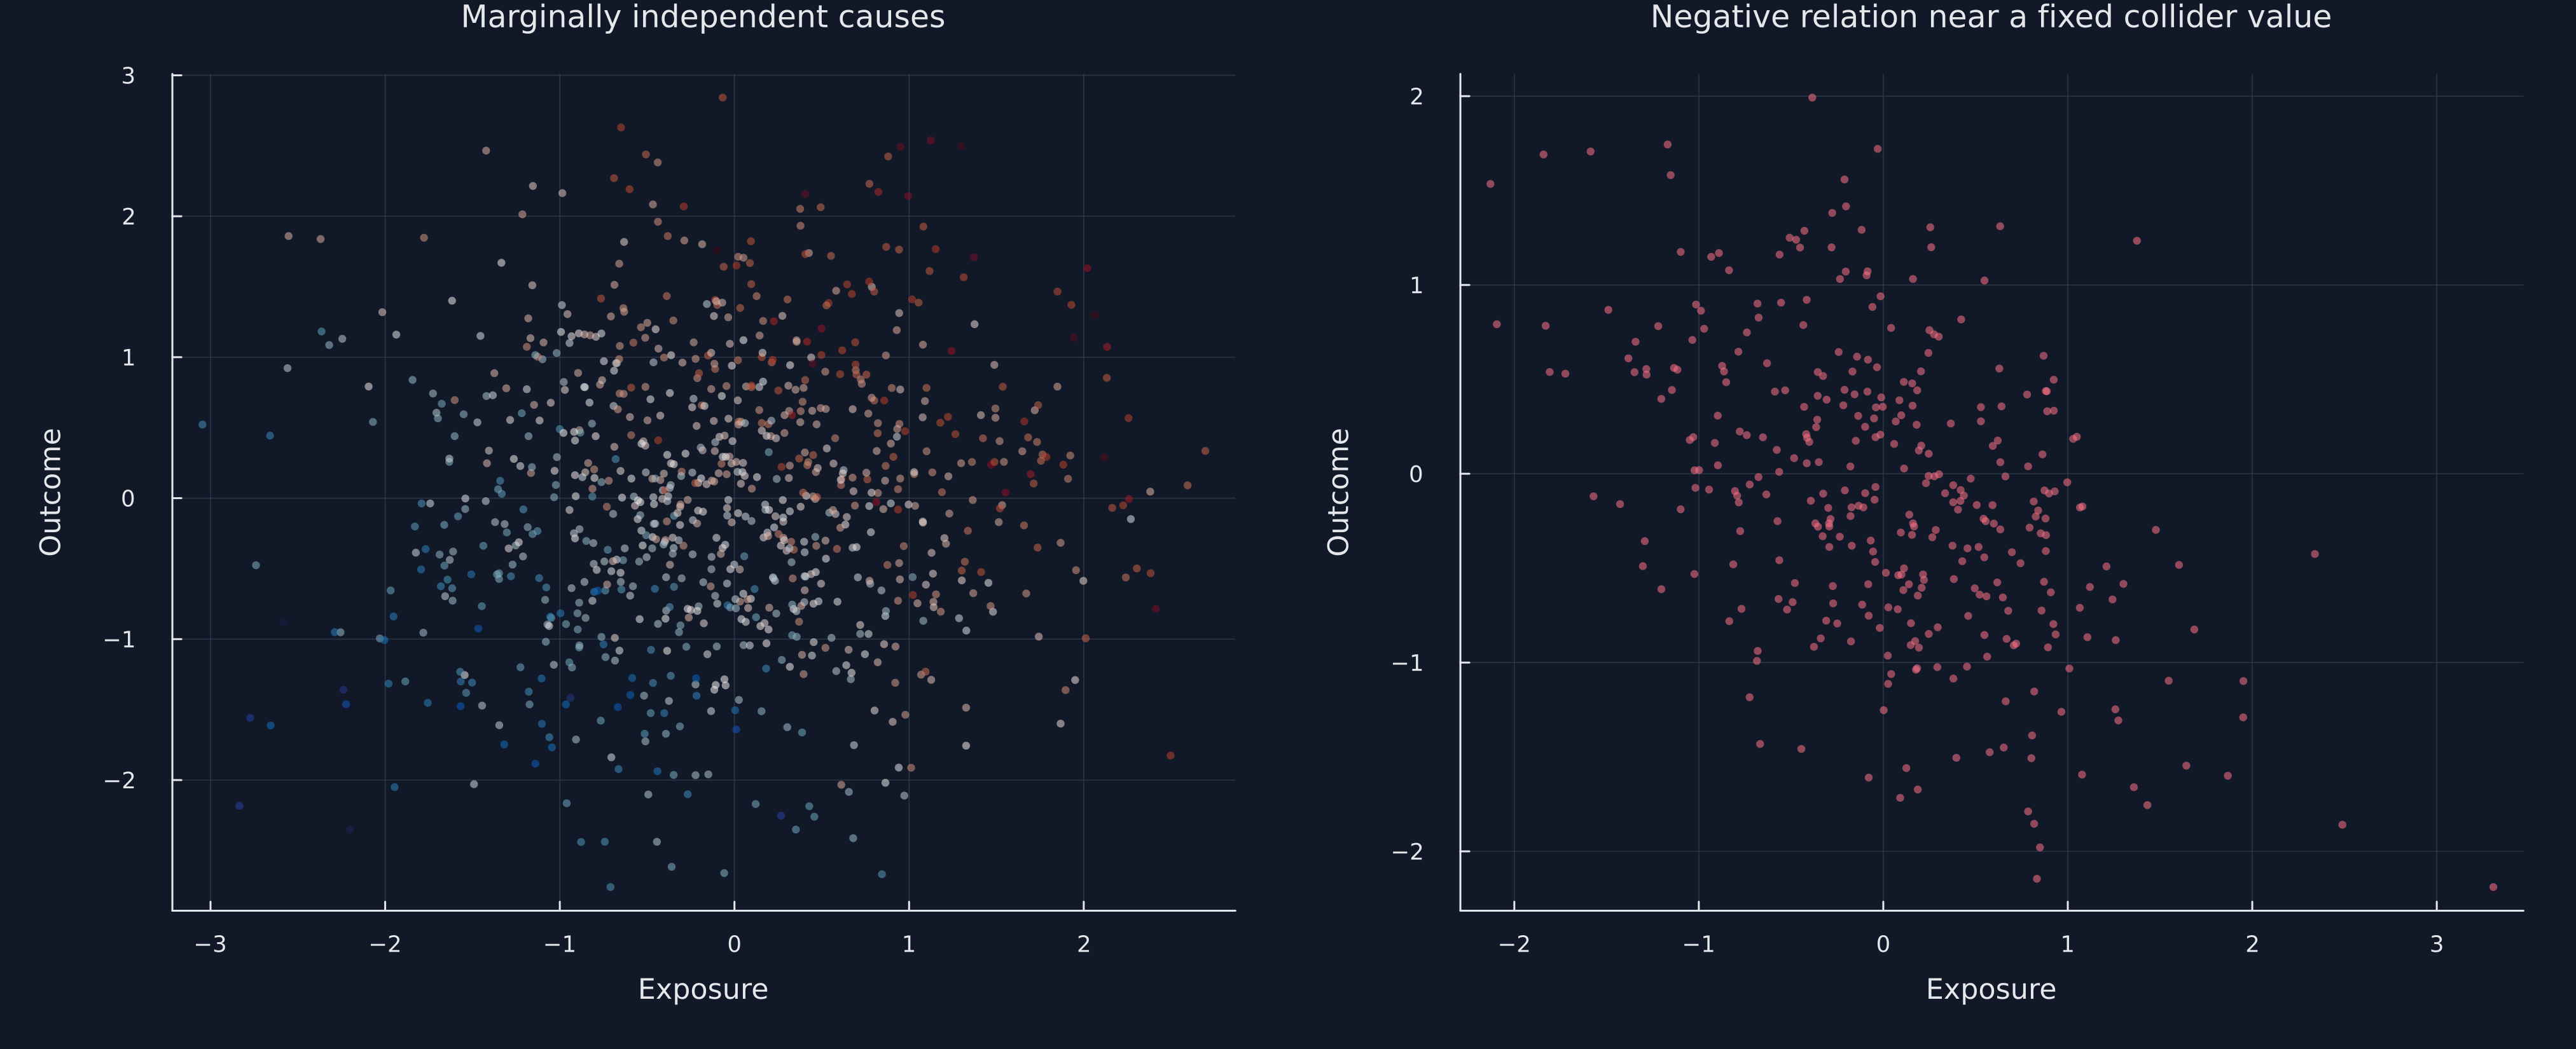

Row,Question,Answer
,String,String
1,Is the collider a cause of the outcome?,No
2,Can conditioning change the exposure coefficient sign?,Yes
3,Can ordinary explained variance improve?,"Yes, for every nonzero outcome link"
4,Are the returned test quantities exact p-values?,No
5,Does the factor calculation use the contemporaneous collider?,"No, it uses a pre-outcome proxy"


In [6]:
simple_draws=primitive_sample(store,5000,0)
simple_exposure,simple_outcome,simple_noise=simple_draws[:,1],simple_draws[:,2],simple_draws[:,3]
simple_collider=simple_exposure+simple_outcome+simple_noise
marginal=manual_diagnostics(simple_outcome,[simple_exposure],["Exposure"])
selected=manual_diagnostics(simple_outcome,[simple_exposure,simple_collider],["Exposure","Collider"])
conditional_table=frame(["Specification","Exposure coefficient","Population target","Collider coefficient","Explained variance"],[("Collider omitted",marginal.coefficients[2],0.,NaN,marginal.r_squared),("Collider included",selected.coefficients[2],-.5,selected.coefficients[3],selected.r_squared),("Conditional covariance identity",-1/3,-1/3,NaN,NaN)])
table(conditional_table,"collider_conditional_selection")
input_checks=frame(["Check","Expected result","Observed result","Passed"],[
    contract_result("Boolean observation count",()->collider_model_diagnostics(1.,1.,1.,true),ArgumentError),
    contract_result("Noninteger observation count",()->collider_model_diagnostics(1.,1.,1.,4.),ArgumentError),
    contract_result("Too few observations",()->collider_model_diagnostics(1.,1.,1.,3),ArgumentError),
    contract_result("Boolean coefficient",()->collider_overcontrolled_coefficients(true,1.,1.),ArgumentError),
    contract_result("Nonfinite coefficient",()->collider_forecast_return(NaN,1.,1.),ArgumentError),
    contract_result("Zero outcome-noise variance",()->generalized_collider_overcontrolled_coefficients(1.,1.,1.;outcome_noise_variance=0.,collider_noise_variance=1.),ArgumentError),
    contract_result("Negative collider-noise variance",()->generalized_collider_overcontrolled_coefficients(1.,1.,1.;outcome_noise_variance=1.,collider_noise_variance=-1.),ArgumentError),
    contract_result("Required variance arguments omitted",()->generalized_collider_overcontrolled_coefficients(1.,1.,1.),UndefKeywordError)])
table(input_checks,"collider_input_checks")
extreme_coefficients=collider_overcontrolled_coefficients(1.,1e308,1.)
extreme_diagnostics=collider_model_diagnostics(1e154,1e200,0.,4)
sign_value=collider_forecast_return(1.,-1e-10,-1e10).misspecified
numerical_table=frame(["Check","Value","Expected value","Passed"],[("Large-link exposure coefficient",extreme_coefficients.beta_hat,-1e-308,isapprox(extreme_coefficients.beta_hat,-1e-308;rtol=1e-15,atol=0.)),("Large-link collider coefficient",extreme_coefficients.theta_hat,1e-308,isapprox(extreme_coefficients.theta_hat,1e-308;rtol=1e-15,atol=0.)),("Representable coefficient variance",extreme_diagnostics.overcontrolled_beta_variance,2.5e-93,isapprox(extreme_diagnostics.overcontrolled_beta_variance,2.5e-93;rtol=1e-14)),("Negative sign survives near cancellation",sign_value,-3.643219731549774e-17,sign_value<0)])
table(numerical_table,"collider_numerical_stability")
draw_index=1:900
selected_band=abs.(simple_collider).<.15
marginal_panel=scatter(simple_exposure[draw_index],simple_outcome[draw_index];marker_z=simple_collider[draw_index],color=:balance,colorbar=false,markersize=2.3,markeralpha=.55,markerstrokewidth=0,label="",xlabel="Exposure",ylabel="Outcome",title="Marginally independent causes")
selected_panel=scatter(simple_exposure[selected_band],simple_outcome[selected_band];color=chapter_palette.rose,markersize=2.3,markeralpha=.55,markerstrokewidth=0,label="",xlabel="Exposure",ylabel="Outcome",title="Negative relation near a fixed collider value")
save_figure(plot(marginal_panel,selected_panel;layout=(1,2),size=(1350,550)),paths,"collider_selection_view")
save_data(DataFrame("Exposure"=>simple_exposure,"Outcome"=>simple_outcome,"Noise"=>simple_noise,"Collider"=>simple_collider,"Selected band"=>selected_band),paths,"collider_selection_values")
section_summary = frame(["Question","Answer"],[["Is the collider a cause of the outcome?","No"],["Can conditioning change the exposure coefficient sign?","Yes"],["Can ordinary explained variance improve?","Yes, for every nonzero outcome link"],["Are the returned test quantities exact p-values?","No"],["Does the factor calculation use the contemporaneous collider?","No, it uses a pre-outcome proxy"]])
table(section_summary,"collider_section_summary")


## Tests

In [7]:
@assert collider_overcontrolled_coefficients(.7,0.,4.)==ColliderCoefficients(.7,0.)
@assert factor_example==StrategyPerformance(1.,-.5)
@assert forecast_example==StrategyPerformance(1.,-.5)
@assert diagnostics==ColliderDiagnostics(.5,2.,.5,.75,1/3,.5,.2,11/20,.05,sqrt(5.),-sqrt(5/11),sqrt(5.),true,false)
@assert !any(threshold_table[threshold_table.Position.=="At","Overcontrolled preferred"])
@assert all(input_checks.Passed)
@assert all(numerical_table.Passed)
assert_artifacts(["collider_graph_and_coefficient","collider_variance_ratio","collider_return_regions","collider_fit_thresholds","collider_expected_signal_paths","collider_selection_view"],["collider_standardized_coefficients","collider_generated_check","collider_general_variance","collider_return_examples","collider_return_boundaries","collider_diagnostic_example","collider_adjusted_threshold","collider_expected_signals","collider_conditional_selection","collider_input_checks","collider_numerical_stability","collider_section_summary"])
